# Predicting Purchase Intent from Online Shopping Sessions

Machine Learning — Assignment 2

This notebook is the working record behind the trained models in `model/` and the
Streamlit app in `app.py`. It walks through the dataset, the preprocessing
decisions, the five required classifiers, and the comparison between them.

**Problem.** Each row is one session on an e-commerce site. Given what the visitor
did — how many pages of each type they opened, how long they spent, the bounce and
exit rates, the month, the traffic source — predict whether that session ended in a
purchase (`Revenue`). This is a binary classification problem, and a strongly
imbalanced one: roughly 15% of sessions convert.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# The reusable code lives in src/ so that the notebook, the training script and
# the Streamlit app all share one definition of the feature schema.
sys.path.insert(0, str(Path.cwd().parent / "src"))

from evaluate import METRIC_ORDER, decision_scores, roc_points, score_model
from preprocessing import (
    CATEGORICAL_FEATURES,
    FEATURES,
    NUMERIC_FEATURES,
    TARGET,
    load_dataset,
    split_data,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

## 1. The dataset

UCI *Online Shoppers Purchasing Intention Dataset* (ID 468), fetched by
`src/download_data.py`. It has 12,330 sessions and 17 features, which clears the
assignment's minimum of 500 instances and 12 features.

In [2]:
frame = load_dataset()
print(f"Shape after de-duplication: {frame.shape[0]:,} rows x {frame.shape[1]} columns")
frame.head()

Loaded 12,330 rows, kept 12,205 after dropping duplicates.
Shape after de-duplication: 12,205 rows x 18 columns


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,0


In [3]:
# Column types, and a check that nothing is missing.
summary = pd.DataFrame({
    "dtype": frame.dtypes.astype(str),
    "missing": frame.isna().sum(),
    "unique": frame.nunique(),
})
summary

,dtype,missing,unique
Administrative,int64,0,27
Administrative_Duration,float64,0,3335
Informational,int64,0,17
Informational_Duration,float64,0,1258
ProductRelated,int64,0,311
ProductRelated_Duration,float64,0,9551
BounceRates,float64,0,1872
ExitRates,float64,0,4777
PageValues,float64,0,2704
SpecialDay,float64,0,6


### Why some integer columns are treated as categorical

`OperatingSystems`, `Browser`, `Region` and `TrafficType` arrive as integers, but
they are ID codes rather than quantities — browser 7 is not "more browser" than
browser 3. Scaling them would invent an ordering that does not exist, so they are
one-hot encoded alongside `Month`, `VisitorType` and `Weekend`.

In [4]:
print("Numeric (scaled):")
for column in NUMERIC_FEATURES:
    print(f"  {column}")
print("\nCategorical (one-hot encoded):")
for column in CATEGORICAL_FEATURES:
    print(f"  {column}  ->  {frame[column].nunique()} levels")

Numeric (scaled):
  Administrative
  Administrative_Duration
  Informational
  Informational_Duration
  ProductRelated
  ProductRelated_Duration
  BounceRates
  ExitRates
  PageValues
  SpecialDay

Categorical (one-hot encoded):
  Month  ->  10 levels
  OperatingSystems  ->  8 levels
  Browser  ->  13 levels
  Region  ->  9 levels
  TrafficType  ->  20 levels
  VisitorType  ->  3 levels
  Weekend  ->  2 levels


## 2. The class imbalance

This is the single most important fact about the dataset, and it shapes every
decision later: the model-selection metric, the use of `class_weight="balanced"`,
and why accuracy on its own is a misleading score here.

Revenue
No purchase    10297
Purchase        1908

Positive rate: 15.63%
A model that always predicts 'no purchase' would score 84.37% accuracy while finding nothing.


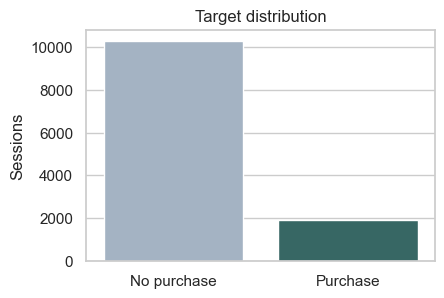

In [5]:
counts = frame[TARGET].value_counts().sort_index()
positive_rate = frame[TARGET].mean()
print(counts.rename({0: "No purchase", 1: "Purchase"}).to_string())
print(f"\nPositive rate: {positive_rate:.2%}")
print(f"A model that always predicts 'no purchase' would score "
      f"{1 - positive_rate:.2%} accuracy while finding nothing.")

figure, axis = plt.subplots(figsize=(4.5, 3))
sns.barplot(x=["No purchase", "Purchase"], y=counts.values, ax=axis,
            palette=["#9fb3c8", "#2f6f6b"])
axis.set_ylabel("Sessions")
axis.set_title("Target distribution")
plt.show()

## 3. What separates a buying session from a browsing one

`PageValues` is the strongest single signal by a wide margin — it is Google
Analytics' estimate of the value of the pages a visitor saw before converting.
`ExitRates` moves the other way: sessions that convert have markedly lower exit
rates.

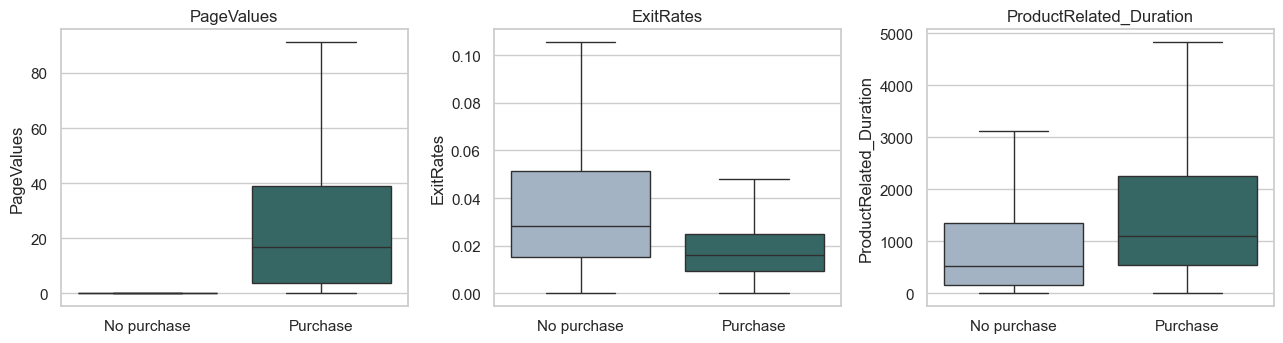

In [6]:
figure, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for axis, column in zip(axes, ["PageValues", "ExitRates", "ProductRelated_Duration"]):
    sns.boxplot(data=frame, x=TARGET, y=column, ax=axis, showfliers=False,
                palette=["#9fb3c8", "#2f6f6b"])
    axis.set_xticklabels(["No purchase", "Purchase"])
    axis.set_xlabel("")
    axis.set_title(column)
plt.tight_layout()
plt.show()

In [7]:
# Conversion rate by month: November and October carry the seasonal peak, and
# February and the summer months are close to flat.
by_month = (frame.groupby("Month")[TARGET]
            .agg(["mean", "size"])
            .sort_values("mean", ascending=False)
            .rename(columns={"mean": "conversion_rate", "size": "sessions"}))
by_month["conversion_rate"] = (by_month["conversion_rate"] * 100).round(1)
by_month

,conversion_rate,sessions
Month,,
Nov,25.5,2982
Oct,20.9,549
Sep,19.2,448
Aug,17.6,433
Jul,15.3,432
Dec,12.7,1706
May,11.0,3329
Mar,10.3,1860
June,10.2,285


In [8]:
# Returning visitors convert less often than new ones here, which is worth
# noticing: the site's new traffic is better qualified than its repeat traffic.
frame.groupby("VisitorType")[TARGET].agg(["mean", "size"]).rename(
    columns={"mean": "conversion_rate", "size": "sessions"}
).round(3)

,conversion_rate,sessions
VisitorType,,
New_Visitor,0.249,1693
Other,0.198,81
Returning_Visitor,0.141,10431


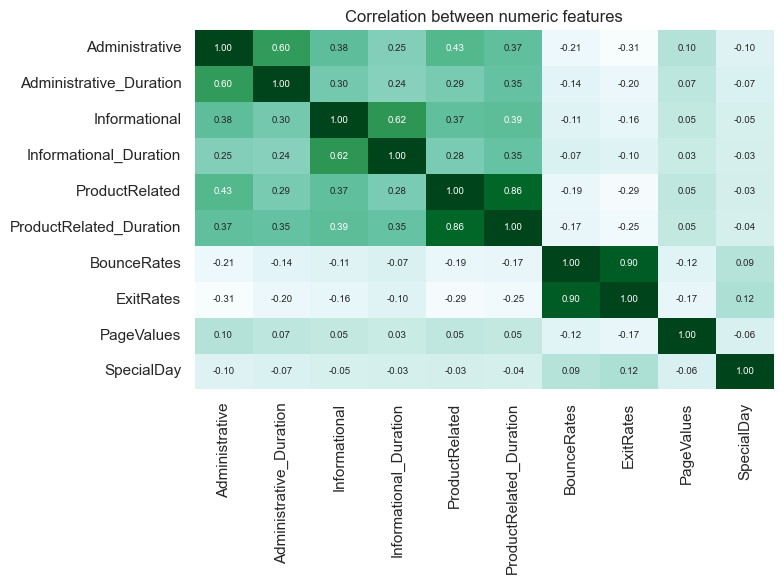

In [9]:
# Correlation among the numeric features. The page-count and duration pairs are
# strongly correlated, as expected - more pages means more time - and BounceRates
# and ExitRates measure nearly the same thing.
figure, axis = plt.subplots(figsize=(8, 6))
sns.heatmap(frame[NUMERIC_FEATURES].corr(), annot=True, fmt=".2f", cmap="BuGn",
            annot_kws={"size": 7}, cbar=False, ax=axis)
axis.set_title("Correlation between numeric features")
plt.tight_layout()
plt.show()

## 4. Train/test split

A stratified 80/20 split, with the 20% held back and never used for fitting or
for choosing hyperparameters. `src/export_test_data.py` writes exactly these rows
to `test_data.csv`, which is the file the Streamlit app scores.

In [10]:
X_train, X_test, y_train, y_test = split_data(frame)
print(f"Train: {len(X_train):,} rows, {y_train.mean():.2%} positive")
print(f"Test:  {len(X_test):,} rows, {y_test.mean():.2%} positive")

Train: 9,764 rows, 15.63% positive
Test:  2,441 rows, 15.65% positive


## 5. Training the five classifiers

`src/train_models.py` does the work. Each model is a `Pipeline` of the shared
preprocessor plus the estimator, and each one's hyperparameters are chosen by
5-fold stratified cross-validation **on the training split only**.

The search optimises F1 rather than accuracy. At a 15% positive rate, accuracy
rewards a model for predicting "no purchase" everywhere; F1 forces it to actually
find the minority class.

In [11]:
from train_models import MODELS, train_all

for name, (stem, estimator, grid) in MODELS.items():
    print(f"{name:24s} {type(estimator).__name__}")
    for key, values in grid.items():
        print(f"{'':24s}   {key.replace('classifier__', '')}: {list(values)}")

Logistic Regression      LogisticRegression
                           C: [0.01, 0.1, 1.0, 10.0]
Decision Tree            DecisionTreeClassifier
                           max_depth: [4, 6, 8, 12, None]
                           min_samples_leaf: [1, 10, 20]
KNN                      KNeighborsClassifier
                           n_neighbors: [5, 15, 25, 50]
                           weights: ['uniform', 'distance']
Naive Bayes              GaussianNB
                           var_smoothing: [np.float64(1e-09), np.float64(1e-08), np.float64(1e-07), np.float64(1e-06), np.float64(1e-05), np.float64(0.0001), np.float64(0.001), np.float64(0.01), np.float64(0.1), np.float64(1.0)]
Support Vector Machine   SVC
                           C: [0.5, 1.0, 5.0]


In [12]:
# Fits all five, saves them to model/, and writes model/metrics.json.
results = train_all()

Loaded 12,330 rows, kept 12,205 after dropping duplicates.
Train: 9,764 rows (15.6% positive) | Test: 2,441 rows (15.6% positive)

Training Logistic Regression ...


/Users/geeta/Desktop/MFML/ml-assignment-classification/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/geeta/Desktop/MFML/ml-assignment-classification/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/geeta/Desktop/MFML/ml-assignment-classification/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/geeta/Desktop/MFML/ml-assignment-classification/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/geeta/Desktop/MFML/ml-assignment-classification/.venv/lib/python

/Users/geeta/Desktop/MFML/ml-assignment-classification/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/geeta/Desktop/MFML/ml-assignment-classification/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/geeta/Desktop/MFML/ml-assignment-classification/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/geeta/Desktop/MFML/ml-assignment-classification/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/geeta/Desktop/MFML/ml-assignment-classification/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/

  best params: {'C': 0.01}
  CV f1: 0.6199
  saved -> model/logistic_regression.joblib
  Accuracy=0.8587  AUC=0.9099  Precision=0.5325  Recall=0.7932  F1=0.6372  MCC=0.5706

Training Decision Tree ...


  best params: {'max_depth': 4, 'min_samples_leaf': 10}
  CV f1: 0.6424
  saved -> model/decision_tree.joblib
  Accuracy=0.8480  AUC=0.9242  Precision=0.5085  Recall=0.8586  F1=0.6388  MCC=0.5807

Training KNN ...


  best params: {'n_neighbors': 5, 'weights': 'uniform'}
  CV f1: 0.4788
  saved -> model/knn.joblib
  Accuracy=0.8734  AUC=0.7958  Precision=0.6622  Recall=0.3901  F1=0.4909  MCC=0.4435

Training Naive Bayes ...
  best params: {'var_smoothing': 0.1}
  CV f1: 0.5165
  saved -> model/naive_bayes.joblib
  Accuracy=0.8161  AUC=0.8418  Precision=0.4419  Recall=0.6675  F1=0.5318  MCC=0.4371

Training Support Vector Machine ...


  best params: {'C': 1.0}
  CV f1: 0.6444
  saved -> model/svm.joblib
  Accuracy=0.8689  AUC=0.9095  Precision=0.5589  Recall=0.7696  F1=0.6476  MCC=0.5805

Wrote model/metrics.json

Held-out test set comparison:
                        Accuracy     AUC  Precision  Recall      F1     MCC
Logistic Regression       0.8587  0.9099     0.5325  0.7932  0.6372  0.5706
Decision Tree             0.8480  0.9242     0.5085  0.8586  0.6388  0.5807
KNN                       0.8734  0.7958     0.6622  0.3901  0.4909  0.4435
Naive Bayes               0.8161  0.8418     0.4419  0.6675  0.5318  0.4371
Support Vector Machine    0.8689  0.9095     0.5589  0.7696  0.6476  0.5805


## 6. Comparison

In [13]:
results.round(4).style.format("{:.4f}").highlight_max(axis=0, color="#e4efed")

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.8587,0.9099,0.5325,0.7932,0.6372,0.5706
Decision Tree,0.8480,0.9242,0.5085,0.8586,0.6388,0.5807
KNN,0.8734,0.7958,0.6622,0.3901,0.4909,0.4435
Naive Bayes,0.8161,0.8418,0.4419,0.6675,0.5318,0.4371
Support Vector Machine,0.8689,0.9095,0.5589,0.7696,0.6476,0.5805


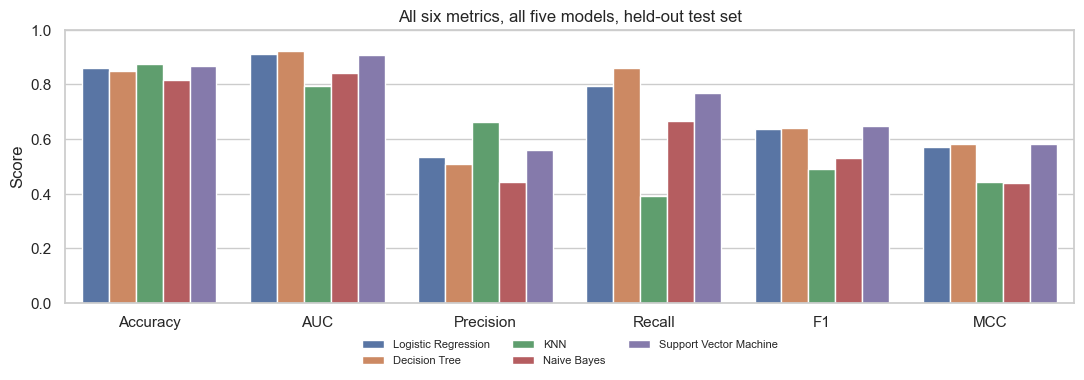

In [14]:
melted = results.reset_index(names="Model").melt(
    id_vars="Model", var_name="Metric", value_name="Score")

figure, axis = plt.subplots(figsize=(11, 4))
sns.barplot(data=melted, x="Metric", y="Score", hue="Model", ax=axis)
axis.set_ylim(0, 1)
axis.set_xlabel("")
axis.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1),
            frameon=False)
axis.set_title("All six metrics, all five models, held-out test set")
plt.tight_layout()
plt.show()

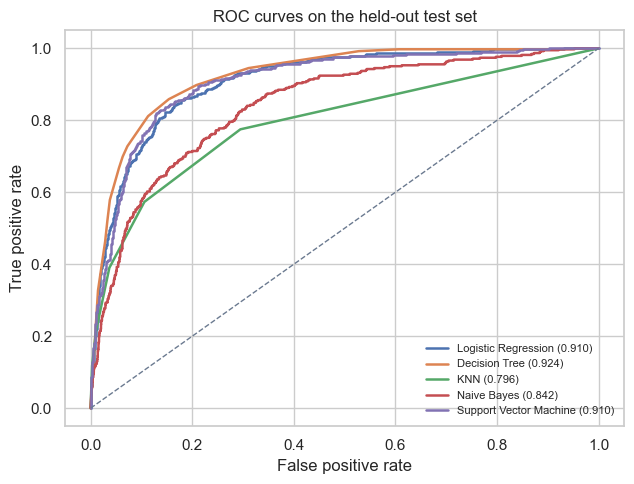

In [15]:
# ROC curves. AUC is threshold-free, so it separates "ranks buyers well" from
# "happens to sit at a good 0.5 cut-off".
import joblib

MODEL_DIR = Path.cwd().parent / "model"
fitted = {name: joblib.load(MODEL_DIR / f"{stem}.joblib")
          for name, (stem, _, _) in MODELS.items()}

figure, axis = plt.subplots(figsize=(6.5, 5))
for name, model in fitted.items():
    fpr, tpr = roc_points(y_test, decision_scores(model, X_test))
    axis.plot(fpr, tpr, linewidth=1.8, label=f"{name} ({results.loc[name, 'AUC']:.3f})")
axis.plot([0, 1], [0, 1], "--", color="#6b7a90", linewidth=1)
axis.set_xlabel("False positive rate")
axis.set_ylabel("True positive rate")
axis.set_title("ROC curves on the held-out test set")
axis.legend(fontsize=8, loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

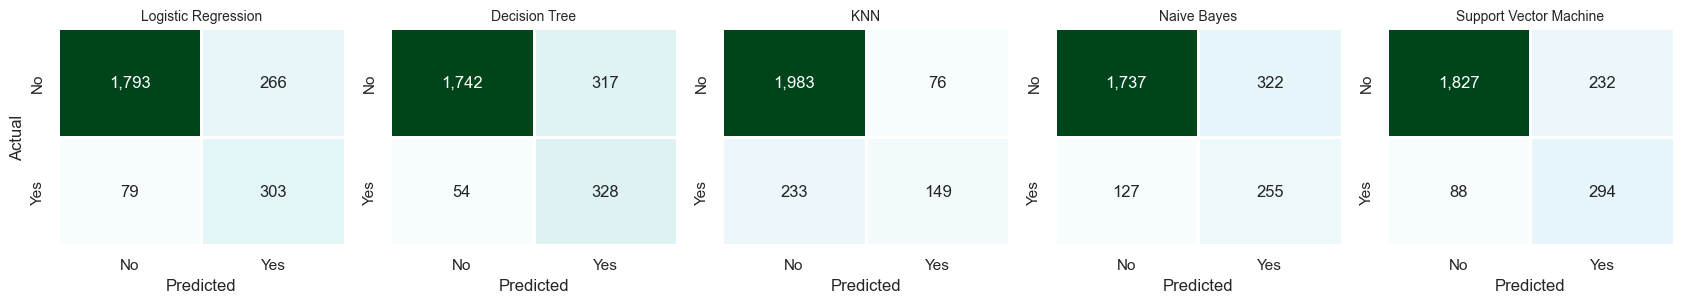

In [16]:
# Confusion matrices side by side. The shape of the errors differs more between
# these models than the headline accuracy numbers suggest.
from evaluate import confusion

figure, axes = plt.subplots(1, 5, figsize=(17, 3.2))
for axis, (name, model) in zip(axes, fitted.items()):
    sns.heatmap(confusion(y_test, model.predict(X_test)), annot=True, fmt=",d",
                cmap="BuGn", cbar=False, ax=axis, linewidths=1, linecolor="white",
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    axis.set_title(name, fontsize=10)
    axis.set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 7. Observations

**Logistic Regression** — a strong, well-behaved baseline. AUC of 0.91 says the
linear decision boundary ranks sessions nearly as well as anything else here,
which tells us most of the signal in this dataset is close to linearly separable
once `PageValues` is in the model. Cross-validation picked heavy regularisation
(`C=0.01`), which the wide one-hot matrix makes unsurprising.

**Decision Tree** — the best AUC (0.924) and by far the best recall (0.859),
catching about six of every seven real purchases. CV chose a shallow tree
(`max_depth=4`), and that shallowness is the point: the tree splits on
`PageValues` and a couple of other strong features and stops before it starts
memorising noise. The cost is precision — just over half its positive calls are
right.

**KNN** — the highest raw accuracy (0.873) and the worst AUC (0.796). That gap is
the whole lesson of this assignment in one row. KNN achieves its accuracy by being
conservative: recall of 0.39 means it misses nearly two thirds of purchases. In a
75-dimensional one-hot space, neighbourhoods are sparse and a 15% minority class is
easily outvoted by its neighbours.

**Naive Bayes** — weakest overall (MCC 0.437). The feature-independence assumption
is badly violated here: `ProductRelated` and `ProductRelated_Duration` are almost
the same variable, as are `BounceRates` and `ExitRates`. It also needed heavy
variance smoothing (`var_smoothing=0.1`) to behave at all, because one-hot columns
for rare browser or traffic codes have near-zero within-class variance and make
the Gaussian likelihood blow up. At the library default it predicted "purchase"
for almost every session and scored 28% accuracy.

**Support Vector Machine** — the best F1 (0.648) and the best balance of the five.
The RBF kernel buys a little over logistic regression on precision at a similar
recall, which suggests a mildly non-linear boundary. It is also the slowest to
train, and the only model whose AUC had to come from `decision_function` rather
than predicted probabilities.

**Overall winner: the Decision Tree**, narrowly. It has the best AUC and the best
recall, and its MCC (0.581) is level with the SVM's (0.580). For this problem
recall is what matters commercially — a missed purchaser is a lost sale, while a
false positive costs only a wasted impression — and the tree is also the one model
a marketing team could read directly. The SVM is the better choice if precision
matters more; the two are statistically indistinguishable on MCC.

A note on accuracy: KNN "wins" on accuracy and is the worst model in the set. On a
15%-positive dataset, accuracy and the other five metrics disagree, and the other
five are right.